# Does longer context help a small character-level transformer?

Daniel Moody (23370157) & Nandakishore Vinayakrishnan (23070854)

**Research question:** with training characters held fixed, does increasing context length from 32 to 128 to 256 lower test bits-per-character for a 4-layer character transformer on TinyShakespeare?

This notebook is the whole experiment. On a T4 GPU runtime, use **Runtime → Run all** (about 1–1.5 hours):

1. **Data.** TinyShakespeare. The last 10% is a fixed test set. The first 90% is cut into 10 folds.
2. **10-fold cross-validation.** For every fold *f* and every context length (32, 128, 256), a fresh transformer is trained on the other nine folds with seed *f*, and its checkpoint is chosen on fold *f*. That is 30 runs. Context 32 is the reference condition; only the context length changes.
3. **N-gram reference.** A smoothed character n-gram is fitted on each fold, with its order and discount chosen on that fold's validation set.
4. **Evaluation.** The primary metric is fixed-target **test** bits-per-character. Each transformer's checkpoint and each n-gram's order and discount are chosen on that run's validation fold, never on the test set. The test set is scored once, at the end of each run, with the chosen model. Set `EVALUATE_TEST = False` in the setup cell to work on validation only while developing, so the test set isn't inspected repeatedly.
5. **Analysis.** Matched comparisons between context lengths on the same fold, error analysis and figures.

**Outputs** (in `results/`):

- `runs.csv`: one row per run, plus one per n-gram fold, with validation and test BPC, chosen step, training time and hardware.
- `summary.json`: everything else, including the data split, settings, n-gram grid, statistics, error analysis, loss by position and training histories.
- `figures.pdf`: every figure.

Checkpoints go in `checkpoints/`, which is on Google Drive in Colab. If the runtime disconnects, Run all again: unfinished runs resume and finished runs are not retrained.

## 1. Setup

In [1]:
# On Colab, work inside Google Drive so checkpoints survive a disconnect.
import os

try:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs("/content/drive/MyDrive/CS6514-AIML", exist_ok=True)
    os.chdir("/content/drive/MyDrive/CS6514-AIML")
except ImportError:
    pass
print(os.getcwd())

Mounted at /content/drive
/content/drive/MyDrive/CS6514-AIML


In [2]:
import json
import math
import platform
import re
import time
import urllib.request
from collections import Counter
from dataclasses import asdict, dataclass
from functools import lru_cache
from itertools import combinations
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib.backends.backend_pdf import PdfPages
from scipy import stats

DATA_URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
DATA_PATH = Path("data/input.txt")
RESULTS_DIR = Path("results")
CHECKPOINT_DIR = Path("checkpoints")
for directory in (DATA_PATH.parent, RESULTS_DIR, CHECKPOINT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"

CONTEXT_LENGTHS = [32, 128, 256]
CONTEXT_PAIRS = list(combinations(CONTEXT_LENGTHS, 2))
N_FOLDS = 10
EVAL_START = 256  # every model scores the same targets: index 256 (the 257th character) of a split onward
NGRAM_MAX_ORDER = 8
NGRAM_DISCOUNTS = [0.5, 0.75, 0.9]
EVALUATE_TEST = True  # False while developing; True only for the final, frozen run
METRICS = {"val_bpc": "validation BPC", "test_bpc": "test BPC"} if EVALUATE_TEST else {"val_bpc": "validation BPC"}

## 2. Data

TinyShakespeare is downloaded from Karpathy's char-rnn repository (MIT licence; the plays are public domain). The last 10% is the fixed test set. The first 90% is cut into 10 contiguous folds. In fold *f*, block *f* is the validation set and the other nine blocks are the training set. Every cut is moved forward to the next line break, so no line is split across sets. The vocabulary comes from the first 90% only.

In [3]:
if not DATA_PATH.exists():
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

text = DATA_PATH.read_text(encoding="utf-8")


def next_line_start(position):
    return text.index("\n", position) + 1


test_start = next_line_start(int(0.9 * len(text)))
dev_text, test_text = text[:test_start], text[test_start:]
fold_bounds = [0] + [next_line_start(int(i * len(dev_text) / N_FOLDS)) for i in range(1, N_FOLDS)] + [len(dev_text)]


def fold_texts(fold):
    val_start, val_end = fold_bounds[fold], fold_bounds[fold + 1]
    return dev_text[:val_start] + dev_text[val_end:], dev_text[val_start:val_end]


vocab = sorted(set(dev_text))
char_to_id = {char: i for i, char in enumerate(vocab)}
VOCAB_SIZE = len(vocab)


def encode(split_text):
    return torch.tensor([char_to_id[char] for char in split_text])


@lru_cache(maxsize=None)
def fold_data(fold):
    fold_train_text, fold_val_text = fold_texts(fold)
    return encode(fold_train_text), encode(fold_val_text)


test_data = encode(test_text)

unseen_chars = {"test": sorted(set(test_text) - set(vocab))}
for fold in range(N_FOLDS):
    fold_train_text, fold_val_text = fold_texts(fold)
    unseen_chars[f"val_fold{fold}"] = sorted(set(fold_val_text) - set(fold_train_text))

data_summary = {
    "total_chars": len(text),
    "n_folds": N_FOLDS,
    "split_chars": {"dev": len(dev_text), "test": len(test_text)},
    "val_chars_by_fold": [fold_bounds[f + 1] - fold_bounds[f] for f in range(N_FOLDS)],
    "vocab_size": VOCAB_SIZE,
    "unseen_chars": unseen_chars,
}
data_summary

{'total_chars': 1115394,
 'n_folds': 10,
 'split_chars': {'dev': 1003856, 'test': 111538},
 'val_chars_by_fold': [100428,
  100383,
  100351,
  100388,
  100386,
  100418,
  100346,
  100402,
  100370,
  100384],
 'vocab_size': 65,
 'unseen_chars': {'test': [],
  'val_fold0': [],
  'val_fold1': [],
  'val_fold2': [],
  'val_fold3': [],
  'val_fold4': [],
  'val_fold5': [],
  'val_fold6': ['$'],
  'val_fold7': [],
  'val_fold8': [],
  'val_fold9': []}}

## 3. Transformer

A GPT-style decoder: pre-LayerNorm blocks, causal self-attention, a GELU MLP, learned position embeddings, and output weights tied to the token embeddings. Only `context_len` changes between conditions. Every step sees 16,384 training characters, so the batch size is 512, 128 or 64.

Seed *s* is used on fold *s*. The position table is created last, and the seed is reset just before the weights are initialised. On the same fold, every weight except the position table therefore starts identical at every context length.

In [4]:
@dataclass
class Config:
    context_len: int
    seed: int
    n_layer: int = 4
    n_head: int = 4
    n_embd: int = 192
    dropout: float = 0.1
    chars_per_step: int = 16384
    max_steps: int = 3000
    lr: float = 1e-3
    min_lr: float = 1e-4
    weight_decay: float = 0.1
    grad_clip: float = 1.0
    eval_interval: int = 250
    eval_batches: int = 20

    @property
    def batch_size(self):
        return self.chars_per_step // self.context_len

    @property
    def fold(self):
        return self.seed

    @property
    def run_name(self):
        return f"ctx{self.context_len}_seed{self.seed}_fold{self.fold}"


class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.n_head = config.n_head
        self.qkv = nn.Linear(config.n_embd, 3 * config.n_embd)
        self.out = nn.Linear(config.n_embd, config.n_embd)
        self.attn_dropout = config.dropout
        self.resid_dropout = nn.Dropout(config.dropout)

    def forward(self, x):
        batch, length, width = x.shape
        q, k, v = (t.view(batch, length, self.n_head, -1).transpose(1, 2) for t in self.qkv(x).split(width, dim=2))
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True, dropout_p=self.attn_dropout if self.training else 0.0)
        return self.resid_dropout(self.out(y.transpose(1, 2).reshape(batch, length, width)))


class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.attn_norm = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.mlp_norm = nn.LayerNorm(config.n_embd)
        self.mlp = nn.Sequential(
            nn.Linear(config.n_embd, 4 * config.n_embd),
            nn.GELU(),
            nn.Linear(4 * config.n_embd, config.n_embd),
            nn.Dropout(config.dropout),
        )

    def forward(self, x):
        x = x + self.attn(self.attn_norm(x))
        return x + self.mlp(self.mlp_norm(x))


def init_weights(module):
    if isinstance(module, (nn.Linear, nn.Embedding)):
        nn.init.normal_(module.weight, std=0.02)
    if isinstance(module, nn.Linear) and module.bias is not None:
        nn.init.zeros_(module.bias)


class CharTransformer(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.token_embedding = nn.Embedding(VOCAB_SIZE, config.n_embd)
        self.embedding_dropout = nn.Dropout(config.dropout)
        self.blocks = nn.Sequential(*[Block(config) for _ in range(config.n_layer)])
        self.final_norm = nn.LayerNorm(config.n_embd)
        self.head = nn.Linear(config.n_embd, VOCAB_SIZE, bias=False)
        self.head.weight = self.token_embedding.weight
        self.position_embedding = nn.Embedding(config.context_len, config.n_embd)
        torch.manual_seed(config.seed)
        self.apply(init_weights)

    def forward(self, ids):
        positions = torch.arange(ids.size(1), device=ids.device)
        x = self.embedding_dropout(self.token_embedding(ids) + self.position_embedding(positions))
        return self.head(self.final_norm(self.blocks(x)))

    def num_params(self):
        return sum(p.numel() for p in self.parameters())

In [5]:
for context_len in CONTEXT_LENGTHS:
    print(f"context {context_len}: {CharTransformer(Config(context_len, seed=0)).num_params():,} parameters")

short_model = CharTransformer(Config(CONTEXT_LENGTHS[0], seed=0)).state_dict()
long_model = CharTransformer(Config(CONTEXT_LENGTHS[-1], seed=0)).state_dict()
assert all(torch.equal(short_model[name], long_model[name]) for name in short_model if name != "position_embedding.weight")
print("Same seed gives identical starting weights apart from the position table")

context 32: 1,798,464 parameters
context 128: 1,816,896 parameters
context 256: 1,841,472 parameters
Same seed gives identical starting weights apart from the position table


## 4. N-gram reference

A character n-gram with interpolated absolute-discounting smoothing. For a history *h* and next character *c*:

P_n(c | h) = max(count(h, c) − d, 0) / count(h) + d · types(h) / count(h) · P_{n−1}(c | shorter h)

types(h) is the number of distinct characters seen after *h*. Histories never seen in training fall back fully to the shorter history. The unigram level uses add-one smoothing, so no character gets probability zero.

In [6]:
class NgramModel:
    def __init__(self, text, max_order):
        self.max_order = max_order
        self.unigram_counts = Counter(text)
        self.total_chars = len(text)
        self.ngram_counts, self.history_counts, self.history_types = {}, {}, {}
        for order in range(2, max_order + 1):
            ngrams = Counter(text[i:i + order] for i in range(len(text) - order + 1))
            history_counts, history_types = Counter(), Counter()
            for ngram, count in ngrams.items():
                history_counts[ngram[:-1]] += count
                history_types[ngram[:-1]] += 1
            self.ngram_counts[order] = ngrams
            self.history_counts[order] = history_counts
            self.history_types[order] = history_types

    def probability_by_order(self, history, char, discount):
        probability = (self.unigram_counts[char] + 1) / (self.total_chars + VOCAB_SIZE)
        probabilities = [probability]
        for order in range(2, self.max_order + 1):
            context = history[-(order - 1):]
            history_count = self.history_counts[order][context]
            if history_count:
                discounted = max(self.ngram_counts[order][context + char] - discount, 0) / history_count
                backoff_weight = discount * self.history_types[order][context] / history_count
                probability = discounted + backoff_weight * probability
            probabilities.append(probability)
        return probabilities

## 5. Metric and evaluation tools

**Fixed-target bits-per-character.** Every model scores the same targets: every character from position 257 of a split onward. A model with context length L predicts each target from the L characters before it, and only the last position of each window is scored. BPC = cross-entropy in nats / ln 2.

Two extra diagnostics are computed on validation:

- **Loss by position.** The loss at every position of the window, which shows how much each extra character of context helps.
- **Error analysis.** The fixed-target bits split by the kind of character being predicted. The categories are speaker headings such as `First Citizen:`, non-letters, letters at the start of a line, letters at the start of a word, and letters in the middle of a word.

In [7]:
def ngram_bpc_by_order(model, split_text, discount):
    bits = np.zeros(model.max_order)
    for t in range(EVAL_START, len(split_text)):
        history = split_text[t - model.max_order + 1:t]
        bits -= np.log2(model.probability_by_order(history, split_text[t], discount))
    return bits / (len(split_text) - EVAL_START)


@torch.no_grad()
def target_bits(model, data, context_len, batch_size=512):
    """Bits for every fixed target; their mean is the fixed-target BPC."""
    model.eval()
    targets = torch.arange(EVAL_START, len(data))
    window = torch.arange(-context_len, 0)
    bits = []
    for batch_targets in targets.split(batch_size):
        logits = model(data[batch_targets[:, None] + window].to(DEVICE))[:, -1]
        bits.append(F.cross_entropy(logits, data[batch_targets].to(DEVICE), reduction="none").cpu() / math.log(2))
    return torch.cat(bits).numpy()


@torch.no_grad()
def bits_by_position(model, data, context_len, stride=64, batch_size=64):
    """Mean bits at each window position, over windows starting every `stride` characters."""
    model.eval()
    starts = torch.arange(0, len(data) - EVAL_START - 1, stride)
    total_nats = torch.zeros(context_len)
    for batch_starts in starts.split(batch_size):
        positions = batch_starts[:, None] + torch.arange(context_len)
        logits = model(data[positions].to(DEVICE))
        total_nats += F.cross_entropy(logits.transpose(1, 2), data[positions + 1].to(DEVICE), reduction="none").sum(0).cpu()
    return total_nats / len(starts) / math.log(2)


SPEAKER_HEADING = re.compile(r"[A-Z][A-Za-z' ]*:\n")


def target_categories(split_text):
    in_heading = np.zeros(len(split_text), dtype=bool)
    line_start = 0
    for line in split_text.splitlines(keepends=True):
        if SPEAKER_HEADING.fullmatch(line):
            in_heading[line_start:line_start + len(line)] = True
        line_start += len(line)
    categories = []
    for t in range(EVAL_START, len(split_text)):
        char, previous = split_text[t], split_text[t - 1]
        if in_heading[t]:
            categories.append("speaker heading")
        elif not char.isalpha():
            categories.append("non-letter")
        elif previous == "\n":
            categories.append("line start")
        elif not previous.isalpha():
            categories.append("word start")
        else:
            categories.append("mid-word")
    return np.array(categories)

## 6. Training loop

AdamW with a cosine learning-rate schedule from 1e-3 down to 1e-4, gradient clipping at 1.0, and fp16 mixed precision on GPU. Every `eval_interval` steps the loop:

- estimates the validation loss on a fixed set of validation batches;
- keeps the checkpoint with the lowest validation loss as `best.pt`, which is the model that gets evaluated;
- saves the full training state to `last.pt`, so an interrupted run picks up where it stopped and a finished run is not retrained.

In [8]:
def get_batch(data, context_len, batch_size, generator):
    starts = torch.randint(len(data) - context_len, (batch_size,), generator=generator)
    positions = starts[:, None] + torch.arange(context_len)
    return data[positions].to(DEVICE), data[positions + 1].to(DEVICE)


def loss_on(model, inputs, targets):
    with torch.autocast(DEVICE, dtype=torch.float16, enabled=USE_AMP):
        logits = model(inputs)
    return F.cross_entropy(logits.flatten(0, 1).float(), targets.flatten())


@torch.no_grad()
def validation_loss(model, config, val_data):
    model.eval()
    generator = torch.Generator().manual_seed(0)
    losses = [loss_on(model, *get_batch(val_data, config.context_len, config.batch_size, generator)).item()
              for _ in range(config.eval_batches)]
    model.train()
    return sum(losses) / len(losses)


def train(config):
    run_dir = CHECKPOINT_DIR / config.run_name
    run_dir.mkdir(parents=True, exist_ok=True)
    last_path, best_path = run_dir / "last.pt", run_dir / "best.pt"
    train_data, val_data = fold_data(config.fold)

    model = CharTransformer(config).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=config.lr, weight_decay=config.weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=config.max_steps, eta_min=config.min_lr)
    scaler = torch.amp.GradScaler(enabled=USE_AMP)
    batch_generator = torch.Generator().manual_seed(config.seed)
    progress = {"step": 0, "best_step": 0, "best_val_loss": math.inf, "train_seconds": 0.0, "history": [],
                "device": torch.cuda.get_device_name() if DEVICE == "cuda" else "cpu"}

    if last_path.exists():
        checkpoint = torch.load(last_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(checkpoint["model"])
        optimizer.load_state_dict(checkpoint["optimizer"])
        scheduler.load_state_dict(checkpoint["scheduler"])
        scaler.load_state_dict(checkpoint["scaler"])
        batch_generator.set_state(checkpoint["batch_generator"].cpu())
        progress = {"device": progress["device"], **checkpoint["progress"]}
        if progress["step"] < config.max_steps:
            print(f"Resuming {config.run_name} from step {progress['step']}")

    torch.manual_seed(config.seed + progress["step"])
    model.train()
    start_time, recent_losses = time.time(), []
    for step in range(progress["step"] + 1, config.max_steps + 1):
        loss = loss_on(model, *get_batch(train_data, config.context_len, config.batch_size, batch_generator))
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), config.grad_clip)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        recent_losses.append(loss.item())

        if step % config.eval_interval == 0:
            val_loss = validation_loss(model, config, val_data)
            progress["history"].append({"step": step, "train_loss": sum(recent_losses) / len(recent_losses), "val_loss": val_loss})
            recent_losses = []
            if val_loss < progress["best_val_loss"]:
                progress.update(best_step=step, best_val_loss=val_loss)
                torch.save(model.state_dict(), best_path)
            progress["step"] = step
            progress["train_seconds"] += time.time() - start_time
            start_time = time.time()
            torch.save({
                "model": model.state_dict(),
                "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict(),
                "scaler": scaler.state_dict(),
                "batch_generator": batch_generator.get_state(),
                "progress": progress,
            }, last_path)
            print(f"step {step:5d} | train {progress['history'][-1]['train_loss']:.4f} | val {val_loss:.4f} "
                  f"| best {progress['best_val_loss']:.4f} @ {progress['best_step']}")

    best_model = CharTransformer(config).to(DEVICE)
    best_model.load_state_dict(torch.load(best_path, map_location=DEVICE))
    return best_model, progress

## 7. Run the experiment

The loop goes fold by fold, training contexts 32, 128 and 256 on each, so an interruption still leaves complete folds. Each model is evaluated straight after training. The test set is scored here too, but nothing in the pipeline reads those numbers until the final report; checkpoints and settings are chosen on validation only.

In [9]:
run_rows, histories, position_curves, category_rows = [], {}, {}, []

for fold in range(N_FOLDS):
    val_data = fold_data(fold)[1]
    categories = target_categories(fold_texts(fold)[1])
    for context_len in CONTEXT_LENGTHS:
        config = Config(context_len, seed=fold)
        print(f"=== {config.run_name} (batch size {config.batch_size}) ===")
        model, progress = train(config)

        val_bits = target_bits(model, val_data, context_len)
        run_rows.append({
            "model": "transformer",
            "context_len": context_len,
            "fold": fold,
            "seed": config.seed,
            "num_params": model.num_params(),
            "best_step": progress["best_step"],
            "train_minutes": round(progress["train_seconds"] / 60, 2),
            "device": progress["device"],
            "val_bpc": float(val_bits.mean()),
            "test_bpc": float(target_bits(model, test_data, context_len).mean()) if EVALUATE_TEST else math.nan,
        })
        histories[config.run_name] = progress["history"]
        position_curves[config.run_name] = bits_by_position(model, val_data, context_len).tolist()
        for category in np.unique(categories):
            selected = categories == category
            category_rows.append({"context_len": context_len, "fold": fold, "category": category,
                                  "targets": int(selected.sum()), "bpc": float(val_bits[selected].mean())})
        print(f"validation BPC {run_rows[-1]['val_bpc']:.4f}, chosen step {progress['best_step']}, "
              f"{run_rows[-1]['train_minutes']:.1f} min on {progress['device']}")

=== ctx32_seed0_fold0 (batch size 512) ===
validation BPC 1.9458, chosen step 2750, 1.7 min on Tesla T4
=== ctx128_seed0_fold0 (batch size 128) ===
validation BPC 1.9483, chosen step 3000, 1.9 min on Tesla T4
=== ctx256_seed0_fold0 (batch size 64) ===
validation BPC 1.9395, chosen step 3000, 2.0 min on Tesla T4
=== ctx32_seed1_fold1 (batch size 512) ===
validation BPC 1.8337, chosen step 3000, 1.8 min on Tesla T4
=== ctx128_seed1_fold1 (batch size 128) ===
validation BPC 1.8253, chosen step 3000, 1.8 min on Tesla T4
=== ctx256_seed1_fold1 (batch size 64) ===
validation BPC 1.8355, chosen step 3000, 2.0 min on Tesla T4
=== ctx32_seed2_fold2 (batch size 512) ===
validation BPC 1.7897, chosen step 3000, 1.8 min on Tesla T4
=== ctx128_seed2_fold2 (batch size 128) ===
validation BPC 1.7923, chosen step 3000, 1.8 min on Tesla T4
=== ctx256_seed2_fold2 (batch size 64) ===
validation BPC 1.8091, chosen step 3000, 1.9 min on Tesla T4
=== ctx32_seed3_fold3 (batch size 512) ===
step   250 | train

## 8. N-gram reference on every fold

For each fold, the n-gram is fitted on the training folds. Its order (1–8) and discount are chosen by validation BPC on that fold, the same way each transformer's checkpoint is chosen on its own fold. The chosen setting is then scored on the test set. The n-gram is deterministic, so each fold needs only one run. This runs on the CPU and takes a few minutes per fold.

In [10]:
ngram_rows, ngram_grid = [], []

for fold in range(N_FOLDS):
    fold_train_text, fold_val_text = fold_texts(fold)
    ngram = NgramModel(fold_train_text, NGRAM_MAX_ORDER)
    fold_grid = [{"fold": fold, "order": order, "discount": discount, "val_bpc": float(bpc)}
                 for discount in NGRAM_DISCOUNTS
                 for order, bpc in enumerate(ngram_bpc_by_order(ngram, fold_val_text, discount), start=1)]
    best = min(fold_grid, key=lambda row: row["val_bpc"])
    ngram_grid += fold_grid
    ngram_rows.append({
        "model": "n-gram",
        "fold": fold,
        "ngram_order": best["order"],
        "ngram_discount": best["discount"],
        "val_bpc": best["val_bpc"],
        "test_bpc": float(ngram_bpc_by_order(ngram, test_text, best["discount"])[best["order"] - 1]) if EVALUATE_TEST else math.nan,
    })
    print(f"fold {fold}: {best['order']}-gram, d={best['discount']}, validation BPC {best['val_bpc']:.4f}")
    del ngram

fold 0: 5-gram, d=0.75, validation BPC 2.2356
fold 1: 5-gram, d=0.75, validation BPC 2.1146
fold 2: 6-gram, d=0.9, validation BPC 2.0790
fold 3: 5-gram, d=0.75, validation BPC 2.2684
fold 4: 5-gram, d=0.75, validation BPC 2.2521
fold 5: 5-gram, d=0.75, validation BPC 2.2233
fold 6: 5-gram, d=0.75, validation BPC 2.1627
fold 7: 5-gram, d=0.75, validation BPC 2.3266
fold 8: 5-gram, d=0.75, validation BPC 2.1813
fold 9: 5-gram, d=0.9, validation BPC 2.3710


## 9. Results

- **Primary metric:** fixed-target test BPC.
- **Secondary:** fixed-target validation BPC, loss by position and BPC by character type, all on validation.
- **Model selection:** each transformer uses the checkpoint with the lowest sampled validation loss during training. Each n-gram uses the order and discount with the lowest validation BPC on its fold.

Fold difficulty varies a lot between folds. The comparison between context lengths is therefore made **within each fold**: Δ = longer-context BPC − shorter-context BPC on the same fold and seed, so a negative Δ favours the longer context. The table reports the mean Δ over the 10 folds, its standard deviation, a 95% t-interval and how many folds favour the longer context.

The folds share most of their training text, so the 10 differences are not fully independent. The interval is therefore somewhat optimistic and is a guide rather than a formal significance test.

In [11]:
runs = pd.DataFrame(run_rows + ngram_rows)
transformers = runs[runs["model"] == "transformer"]
ngrams = runs[runs["model"] == "n-gram"]


def by_fold(metric):
    return transformers.pivot(index="fold", columns="context_len", values=metric)


def matched_deltas(metric):
    table = by_fold(metric)
    rows = []
    for shorter, longer in CONTEXT_PAIRS:
        delta = (table[longer] - table[shorter]).dropna()
        n = len(delta)
        half_width = stats.t.ppf(0.975, n - 1) * delta.std() / math.sqrt(n) if n > 1 else math.nan
        rows.append({
            "comparison": f"{shorter} → {longer}",
            "n_folds": n,
            "mean_delta": delta.mean(),
            "sd_delta": delta.std(),
            "ci95_low": delta.mean() - half_width,
            "ci95_high": delta.mean() + half_width,
            "folds_favouring_longer": int((delta < 0).sum()),
            "deltas_by_fold": {int(fold): round(float(value), 5) for fold, value in delta.items()},
        })
    return pd.DataFrame(rows)


def per_condition(metric):
    rows = [{"condition": f"context {context_len}", **transformers[transformers["context_len"] == context_len][metric].agg(["mean", "std", "min", "max", "count"]).to_dict()}
            for context_len in CONTEXT_LENGTHS]
    rows.append({"condition": "n-gram", **ngrams[metric].agg(["mean", "std", "min", "max", "count"]).to_dict()})
    return pd.DataFrame(rows)


deltas = {metric: matched_deltas(metric) for metric in METRICS}
conditions = {metric: per_condition(metric) for metric in METRICS}

category_results = pd.DataFrame(category_rows)
category_table = category_results.pivot_table(index=["category", "fold"], columns="context_len", values="bpc")
category_deltas = category_table.sub(category_table[CONTEXT_LENGTHS[0]], axis=0).drop(columns=CONTEXT_LENGTHS[0])

for metric, label in METRICS.items():
    print(f"\n{label.upper()}")
    display(conditions[metric].round(4))
    display(deltas[metric].drop(columns="deltas_by_fold").round(4))
    for row in deltas[metric].itertuples():
        print(f"  {row.comparison}: mean Δ {row.mean_delta:+.4f} BPC (95% CI {row.ci95_low:+.4f} to {row.ci95_high:+.4f}), "
              f"longer context better on {row.folds_favouring_longer}/{row.n_folds} folds")

print("\nVALIDATION BPC BY CHARACTER TYPE (mean over folds)")
display(category_results.pivot_table(index="category", columns="context_len", values="bpc").round(4))


VALIDATION BPC


,condition,mean,std,min,max,count
0,context 32,1.9191,0.0801,1.7897,2.0361,10.0
1,context 128,1.9161,0.0792,1.7923,2.0339,10.0
2,context 256,1.9227,0.0761,1.8091,2.0380,10.0
3,n-gram,2.2215,0.0904,2.0790,2.3710,10.0


,comparison,n_folds,mean_delta,sd_delta,ci95_low,ci95_high,folds_favouring_longer
0,32 → 128,10,-0.0030,0.0057,-0.0070,0.0011,5
1,32 → 256,10,0.0036,0.0100,-0.0036,0.0108,4
2,128 → 256,10,0.0066,0.0102,-0.0008,0.0139,2


  32 → 128: mean Δ -0.0030 BPC (95% CI -0.0070 to +0.0011), longer context better on 5/10 folds
  32 → 256: mean Δ +0.0036 BPC (95% CI -0.0036 to +0.0108), longer context better on 4/10 folds
  128 → 256: mean Δ +0.0066 BPC (95% CI -0.0008 to +0.0139), longer context better on 2/10 folds

TEST BPC


,condition,mean,std,min,max,count
0,context 32,2.1335,0.1087,2.0866,2.4420,10.0
1,context 128,2.1295,0.1061,2.0819,2.4301,10.0
2,context 256,2.1324,0.1077,2.0809,2.4378,10.0
3,n-gram,2.4954,0.1315,2.4454,2.8689,10.0


,comparison,n_folds,mean_delta,sd_delta,ci95_low,ci95_high,folds_favouring_longer
0,32 → 128,10,-0.0039,0.0094,-0.0107,0.0028,7
1,32 → 256,10,-0.0010,0.0110,-0.0089,0.0069,6
2,128 → 256,10,0.0029,0.0128,-0.0062,0.0121,4


  32 → 128: mean Δ -0.0039 BPC (95% CI -0.0107 to +0.0028), longer context better on 7/10 folds
  32 → 256: mean Δ -0.0010 BPC (95% CI -0.0089 to +0.0069), longer context better on 6/10 folds
  128 → 256: mean Δ +0.0029 BPC (95% CI -0.0062 to +0.0121), longer context better on 4/10 folds

VALIDATION BPC BY CHARACTER TYPE (mean over folds)


context_len,32,128,256
category,,,
line start,4.2840,4.2215,4.1236
mid-word,1.5639,1.5865,1.6070
non-letter,1.2907,1.2364,1.2372
speaker heading,1.4614,1.4502,1.4125
word start,3.9679,3.9644,3.9730


## 10. Figures

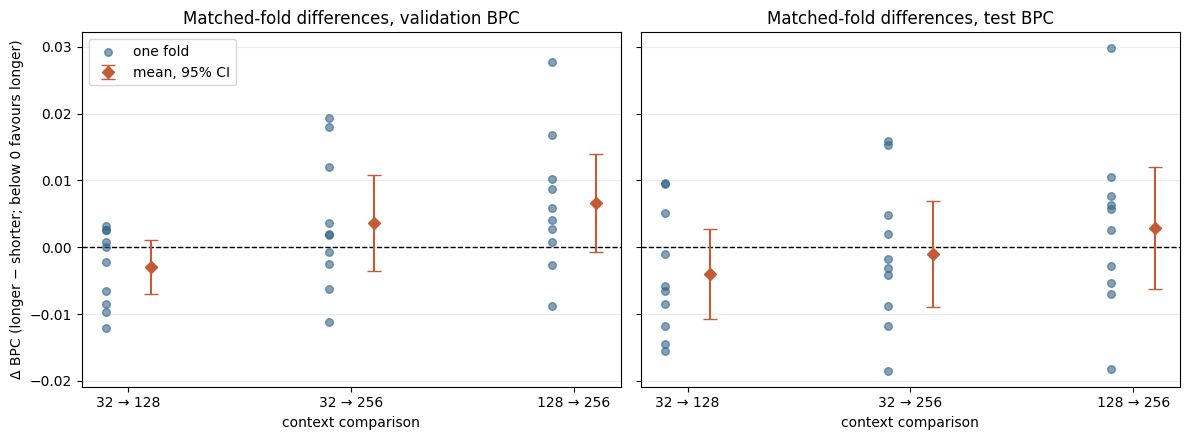

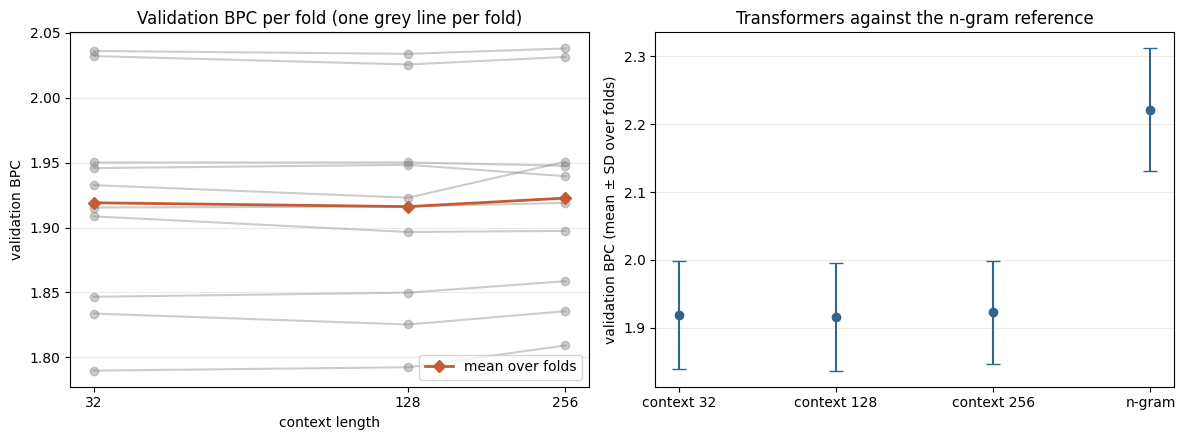

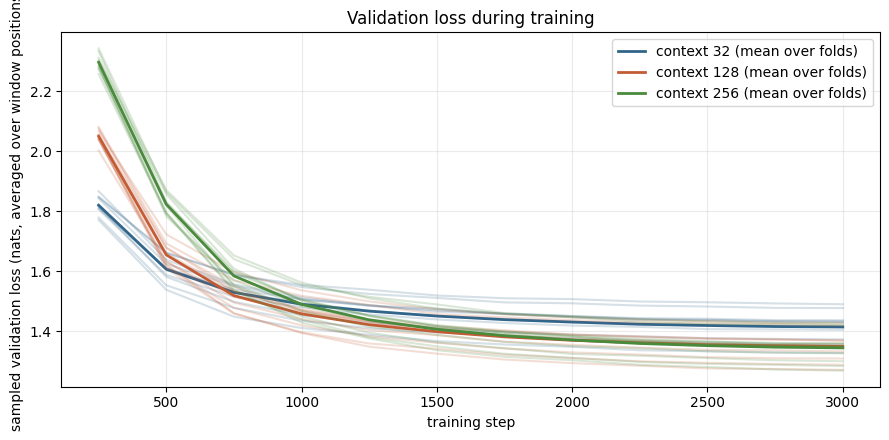

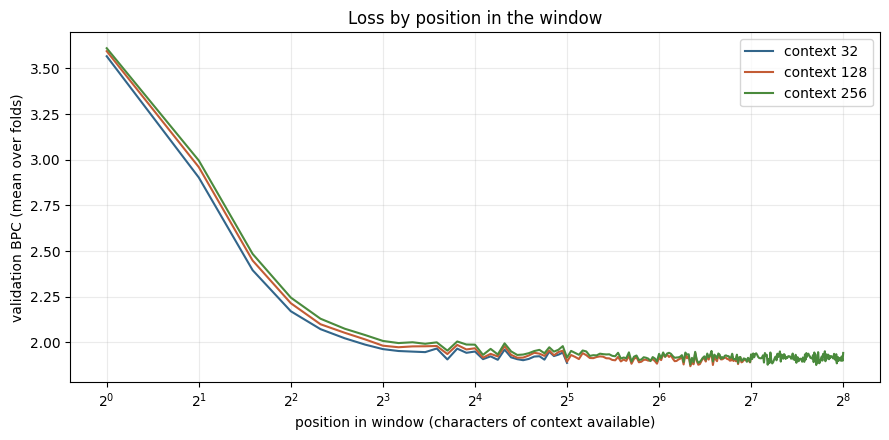

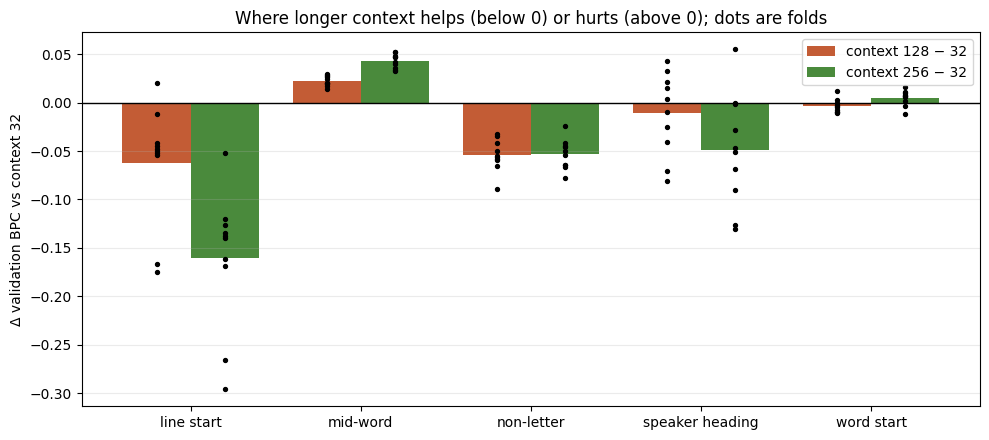

In [12]:
CONTEXT_COLOURS = {context_len: colour for context_len, colour in zip(CONTEXT_LENGTHS, ["#32658a", "#c35c35", "#4a8a3c"])}
figures = []

# 1. Matched differences: the main evidence.
fig, axes = plt.subplots(1, len(METRICS), figsize=(6 * len(METRICS), 4.5), sharey=True)
axes = np.atleast_1d(axes)
for ax, (metric, label) in zip(axes, METRICS.items()):
    for x, row in enumerate(deltas[metric].itertuples()):
        values = list(row.deltas_by_fold.values())
        ax.scatter(np.full(len(values), x - 0.1), values, color="#32658a", alpha=0.6, s=30, zorder=3,
                   label="one fold" if x == 0 else None)
        ax.errorbar(x + 0.1, row.mean_delta, yerr=[[row.mean_delta - row.ci95_low], [row.ci95_high - row.mean_delta]],
                    fmt="D", color="#c35c35", capsize=5, zorder=4, label="mean, 95% CI" if x == 0 else None)
    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set_xticks(range(len(CONTEXT_PAIRS)), [f"{s} → {l}" for s, l in CONTEXT_PAIRS])
    ax.set_xlabel("context comparison")
    ax.set_title(f"Matched-fold differences, {label}")
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("Δ BPC (longer − shorter; below 0 favours longer)")
axes[0].legend()
figures.append(fig)

# 2. Every fold's score, and the n-gram reference.
table = by_fold("val_bpc")
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.5))
for fold, values in table.iterrows():
    left.plot(CONTEXT_LENGTHS, values[CONTEXT_LENGTHS], marker="o", color="grey", alpha=0.4)
left.plot(CONTEXT_LENGTHS, table[CONTEXT_LENGTHS].mean(), marker="D", color="#c35c35", linewidth=2, label="mean over folds")
left.set_xscale("log", base=2)
left.set_xticks(CONTEXT_LENGTHS, CONTEXT_LENGTHS)
left.set_xlabel("context length")
left.set_ylabel("validation BPC")
left.set_title("Validation BPC per fold (one grey line per fold)")
left.legend()
summary_rows = conditions["val_bpc"]
right.errorbar(range(len(summary_rows)), summary_rows["mean"], yerr=summary_rows["std"], fmt="o", capsize=5, color="#32658a")
right.set_xticks(range(len(summary_rows)), summary_rows["condition"])
right.set_ylabel("validation BPC (mean ± SD over folds)")
right.set_title("Transformers against the n-gram reference")
for ax in (left, right):
    ax.grid(axis="y", alpha=0.25)
figures.append(fig)

# 3. Training curves.
fig, ax = plt.subplots(figsize=(9, 4.5))
for context_len in CONTEXT_LENGTHS:
    curves = [histories[Config(context_len, seed=fold).run_name] for fold in range(N_FOLDS)]
    steps = [point["step"] for point in curves[0]]
    for curve in curves:
        ax.plot(steps, [point["val_loss"] for point in curve], color=CONTEXT_COLOURS[context_len], alpha=0.2)
    ax.plot(steps, np.mean([[point["val_loss"] for point in curve] for curve in curves], axis=0),
            color=CONTEXT_COLOURS[context_len], linewidth=2, label=f"context {context_len} (mean over folds)")
ax.set_xlabel("training step")
ax.set_ylabel("sampled validation loss (nats, averaged over window positions)")
ax.set_title("Validation loss during training")
ax.grid(alpha=0.25)
ax.legend()
figures.append(fig)

# 4. Loss by position in the window.
fig, ax = plt.subplots(figsize=(9, 4.5))
for context_len in CONTEXT_LENGTHS:
    curve = np.mean([position_curves[Config(context_len, seed=fold).run_name] for fold in range(N_FOLDS)], axis=0)
    ax.plot(np.arange(1, context_len + 1), curve, color=CONTEXT_COLOURS[context_len], label=f"context {context_len}")
ax.set_xscale("log", base=2)
ax.set_xlabel("position in window (characters of context available)")
ax.set_ylabel("validation BPC (mean over folds)")
ax.set_title("Loss by position in the window")
ax.grid(alpha=0.25)
ax.legend()
figures.append(fig)

# 5. Error analysis by character type.
category_order = list(category_deltas.index.get_level_values("category").unique())
fig, ax = plt.subplots(figsize=(10, 4.5))
width = 0.8 / len(category_deltas.columns)
for i, context_len in enumerate(category_deltas.columns):
    x = np.arange(len(category_order)) + (i - (len(category_deltas.columns) - 1) / 2) * width
    ax.bar(x, category_deltas[context_len].groupby(level="category").mean().reindex(category_order), width,
           color=CONTEXT_COLOURS[context_len], label=f"context {context_len} − {CONTEXT_LENGTHS[0]}")
    for xi, category in zip(x, category_order):
        fold_values = category_deltas.loc[category, context_len]
        ax.scatter(np.full(len(fold_values), xi), fold_values, color="black", s=8, zorder=3)
ax.axhline(0, color="black", linewidth=1)
ax.set_xticks(np.arange(len(category_order)), category_order)
ax.set_ylabel(f"Δ validation BPC vs context {CONTEXT_LENGTHS[0]}")
ax.set_title("Where longer context helps (below 0) or hurts (above 0); dots are folds")
ax.grid(axis="y", alpha=0.25)
ax.legend()
figures.append(fig)

with PdfPages(RESULTS_DIR / "figures.pdf") as pdf:
    for fig in figures:
        fig.tight_layout()
        pdf.savefig(fig)
plt.show()

## 11. Save outputs

In [13]:
runs.to_csv(RESULTS_DIR / "runs.csv", index=False)

summary = {
    "evaluate_test": EVALUATE_TEST,
    "research_question": "With training characters held fixed, does increasing context length from 32 to 128 to 256 "
                         "lower test bits-per-character for a 4-layer character transformer on TinyShakespeare?",
    "data": data_summary,
    "design": {
        "context_lengths": CONTEXT_LENGTHS,
        "folds": N_FOLDS,
        "seed_per_fold": "seed f is used on fold f",
        "eval_start": EVAL_START,
        "transformer_config": {key: value for key, value in asdict(Config(CONTEXT_LENGTHS[0], seed=0)).items()
                               if key not in ("context_len", "seed")},
        "ngram_orders": list(range(1, NGRAM_MAX_ORDER + 1)),
        "ngram_discounts": NGRAM_DISCOUNTS,
    },
    "compute": {
        "devices": sorted(transformers["device"].unique()),
        "transformer_runs": len(transformers),
        "total_train_minutes": round(transformers["train_minutes"].sum(), 1),
        "train_minutes_by_context": transformers.groupby("context_len")["train_minutes"].mean().round(2).to_dict(),
        "num_params_by_context": transformers.groupby("context_len")["num_params"].first().to_dict(),
        "efficiency": "fp16 mixed precision (torch.autocast + GradScaler); fused scaled_dot_product_attention",
        "environment": {
            "python": platform.python_version(),
            "torch": torch.__version__,
            "numpy": np.__version__,
            "pandas": pd.__version__,
            "scipy": scipy.__version__,
            "matplotlib": matplotlib.__version__,
        },
    },
    "results": {metric: {"by_condition": conditions[metric].to_dict("records"), "matched_deltas": deltas[metric].to_dict("records")}
                for metric in METRICS},
    "error_analysis": category_rows,
    "ngram_grid": ngram_grid,
    "loss_by_position": position_curves,
    "training_history": histories,
}


def to_builtin(value):
    return value.item() if hasattr(value, "item") else str(value)


(RESULTS_DIR / "summary.json").write_text(json.dumps(summary, indent=2, default=to_builtin))
print("Wrote", ", ".join(str(RESULTS_DIR / name) for name in ["runs.csv", "summary.json", "figures.pdf"]))

Wrote results/runs.csv, results/summary.json, results/figures.pdf
